# Lab 3a - Iris Classification

## Import libraries and Data

In [ ]:
# import required libraries
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import Image
from pydotplus import graph_from_dot_data
from sklearn import metrics
from sklearn.datasets import load_iris
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.tree import DecisionTreeClassifier, export_graphviz
from IPython.core.formatters import StringIO


In [73]:
iris = load_iris(as_frame=True)
df = iris.frame
df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [74]:
df['species'] = df['target'].map(dict(enumerate(iris.target_names)))
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


## Exploration

In [75]:
# run standard checks
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
 5   species            150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 7.2 KB


In [76]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [77]:
df.shape

(150, 6)

In [78]:
df.duplicated().sum()

np.int64(1)

In [79]:
# No indication duplicate is incorrect data, no unique identifiers so it will remain.
df[df.duplicated()]

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
142,5.8,2.7,5.1,1.9,2,virginica


In [80]:
df.isna().sum()

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
species              0
dtype: int64

In [81]:
# Equally balanced target
df['species'].value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

## Cleaning

In [82]:
# drop unnecessary target column to avoid leakage.
df_updated = df.drop('target', axis=1)
df_updated

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


## Visualisation

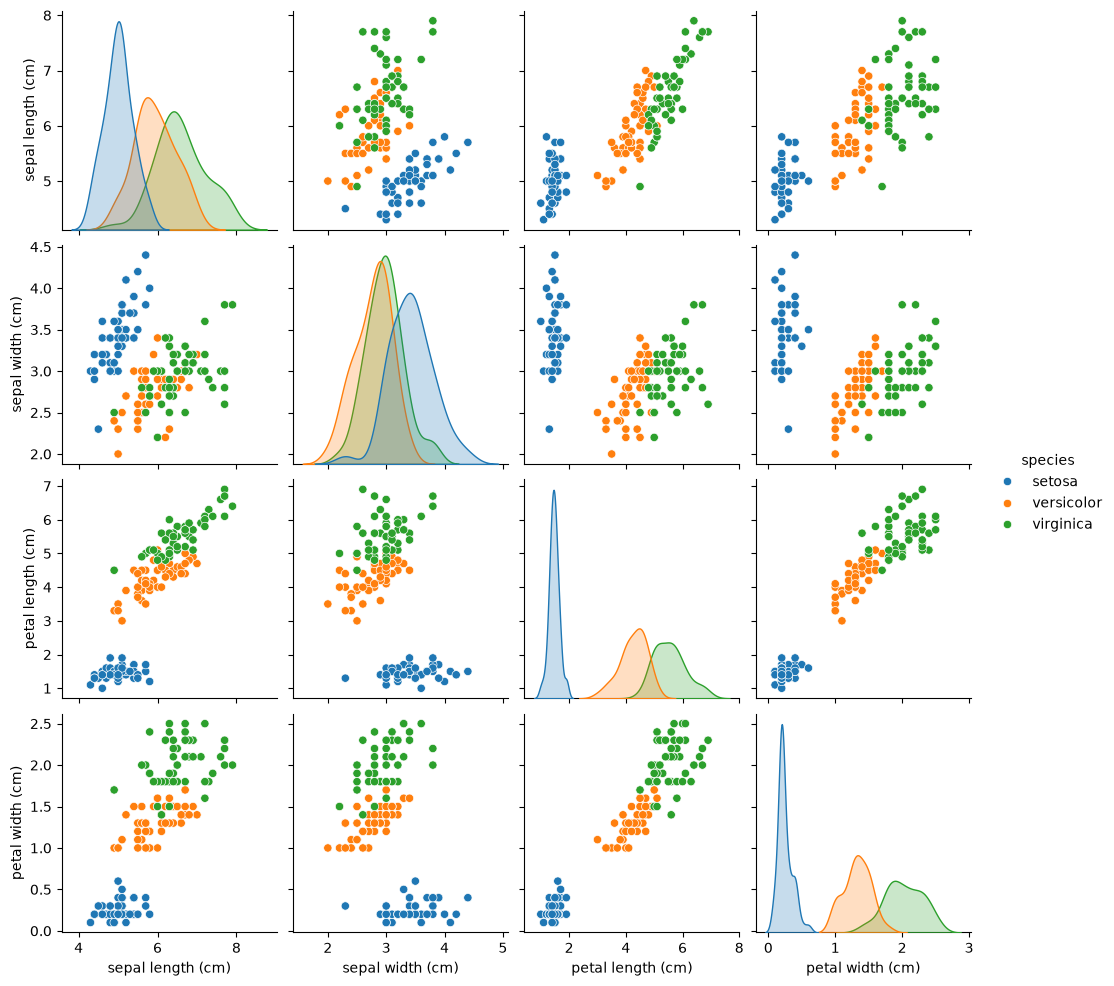

In [83]:
# Setosa is quite separated, the other two overlap somewhat in some features.
sns.pairplot(df.drop(columns='target'), hue='species')

<Axes: >

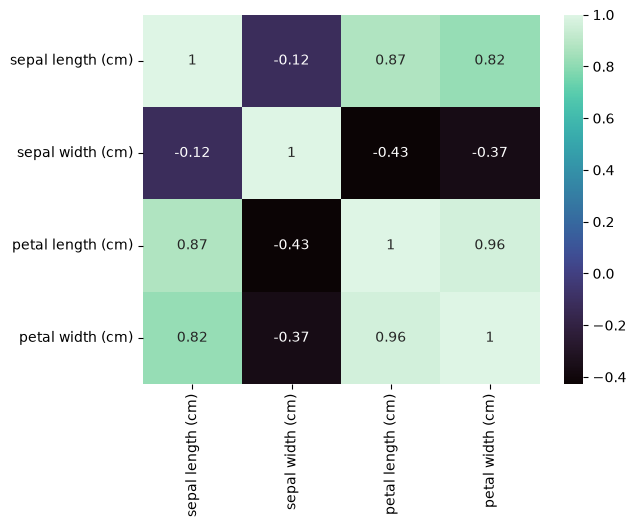

In [84]:
# In general, sepal width has low correlation.
sns.heatmap(df[iris.feature_names].corr(), annot=True, cmap='mako')

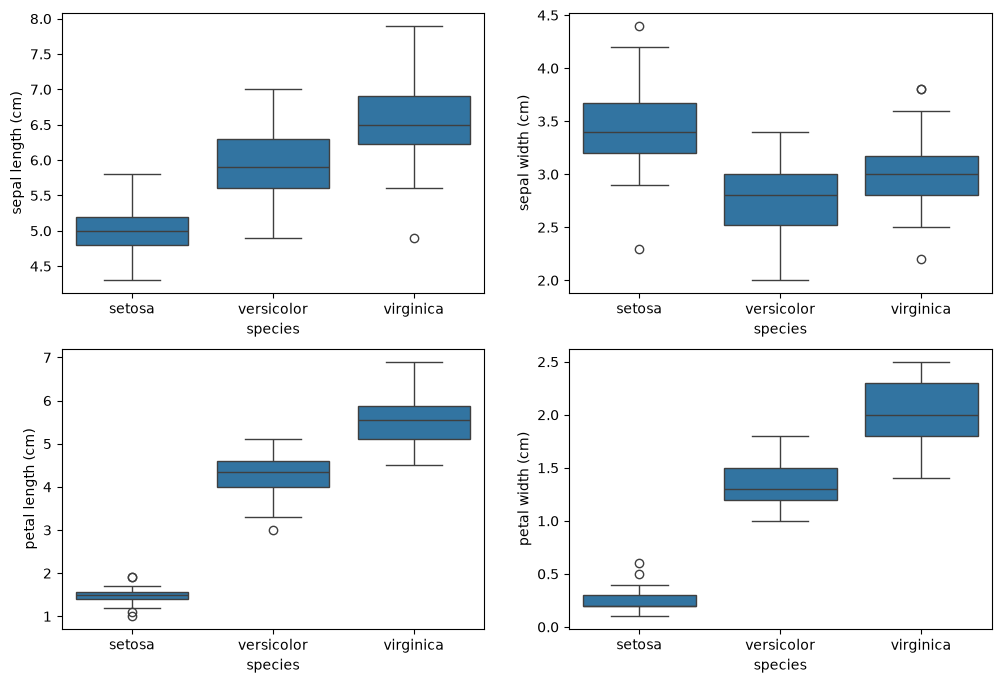

In [85]:
# A few outliers exist in for each species but non are particularly extreme.
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, iris.feature_names):
    sns.boxplot(data=df, x='species', y=col, ax=ax)

## Modelling

In [86]:
# Select Features and model
X = df_updated.drop(columns='species')
y = df_updated['species']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, stratify=y, test_size=0.2, random_state=37
)

In [87]:
model = DecisionTreeClassifier(random_state=37)

# Run cross validation to evaluate on the training set.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=37)
cv_results = cross_validate(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring=('accuracy', 'f1_macro', 'precision_macro', 'recall_macro'),
    return_train_score=True,
)

pd.DataFrame(cv_results).agg(['mean', 'std']).T

,mean,std
fit_time,0.001107,0.000216
score_time,0.002975,0.000484
test_accuracy,0.966667,0.018634
train_accuracy,1.000000,0.000000
test_f1_macro,0.966536,0.018707
train_f1_macro,1.000000,0.000000
test_precision_macro,0.970370,0.016563
train_precision_macro,1.000000,0.000000
test_recall_macro,0.966667,0.018634
train_recall_macro,1.000000,0.000000


In [88]:
# Fit on the full training set and predict the test set
model.fit(X_train, y_train)
predictions = model.predict(X_test)

## Results

In [89]:
# Score on the test set.
print(metrics.classification_report(y_test, predictions))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



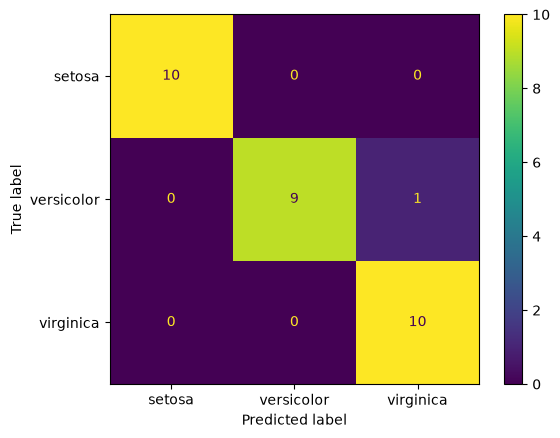

In [90]:
# Score on the test set.
metrics.ConfusionMatrixDisplay.from_predictions(y_test, predictions)

## New Observation

In [91]:
observation = [[5, 4, 3, 2]]
new_predict = model.predict(observation)
new_predict

/Users/Rory/Documents/programming/aiml-labs/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


array([np.str_('virginica')], dtype=object)

In [92]:
# Porbability it is virginica is 100%
model.predict_proba(observation)

/Users/Rory/Documents/programming/aiml-labs/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


array([[0., 0., 1.]])

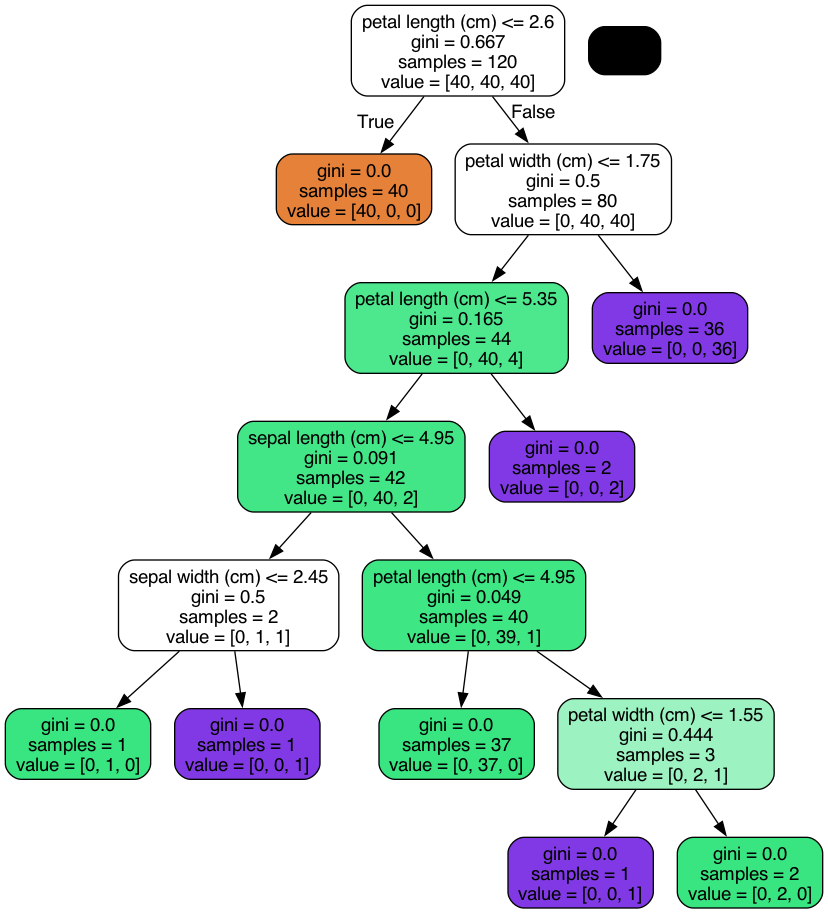

In [100]:
dot_data = export_graphviz(
    model,
    feature_names=list(X.columns),
    filled=True,
    rounded=True,
)
graph = graph_from_dot_data(dot_data)
Image(graph.create_png())